In [37]:
import numpy as np 
from math import sqrt 
import matplotlib.pyplot as plt 
import pandas as pd   


In [44]:
def initialize(dim):
    w1 = np.random.rand(dim)
    w0 = np.random.rand()
    return w1, w0 

def compute_cost(X, Y, y_hat):
    m = len(Y)
    cost = (1 / (2 * m)) * np.sum(np.square(y_hat - Y))
    return cost 

def predict_y(X, w1, w0):
    if len(w1) == 1:
        w1 = w1[0]
        return X * w1 + w0
    return np.dot(X, w1) + w0

def update_parameters(X, Y, y_hat, cost, w0, w1, learning_rate):
    m = len(Y)
    db = np.sum(y_hat - Y) / m
    dw = np.dot(y_hat - Y, X) / m
    w0_new = w0 - learning_rate * db
    w1_new = w1 - learning_rate * dw
    return w0_new, w1_new 

def run_gradient_descent(X, Y, alpha, max_iterations, stopping_threshold=1e-6):
    dims = 1 
    if len(X.shape) > 1:
        dims = X.shape[1]
    w1, w0 = initialize(dims)
    previous_cost = None
    cost_history = np.zeros(max_iterations)
    w0_history = np.zeros(max_iterations)
    w1_history = np.zeros(max_iterations)

    for itr in range(max_iterations):
        y_hat = predict_y(X, w1, w0)
        cost = compute_cost(X, Y, y_hat)
        
        if previous_cost is not None and abs(previous_cost - cost) <= stopping_threshold:
            break 

        cost_history[itr] = cost 
        w0_history[itr] = w0
        w1_history[itr] = w1[0] if isinstance(w1, np.ndarray) else w1  # fix deprecated warning
        previous_cost = cost 

        w0, w1 = update_parameters(X, Y, y_hat, cost, w0, w1, alpha)

    return w0, w1, cost_history, w0_history, w1_history

def plot_cost_history(cost_history):
    plt.plot(range(1, len(cost_history) + 1), cost_history, color="blue")
    plt.rcParams["figure.figsize"] = (10, 6)
    plt.grid()
    plt.xlabel("Number of iterations")
    plt.ylabel("Cost (J)")
    plt.title("Convergence of Gradient Descent")
    plt.show()

def abline(slope, intercept):
    axes = plt.gca()
    x_vals = np.array(axes.get_xlim())
    y_vals = intercept + slope * x_vals 
    plt.plot(x_vals, y_vals, '--', color="red")

def plot_fit(data, w1, w0, cost, itr, pdf=0): 
    cost = round(cost, 2)
    plt.scatter(x=data.temp_c, y=data.temp_f)
    abline(w1, w0)
    plt.rcParams["figure.figsize"] = (10, 6)
    plt.grid()
    plt.xlabel("Temperature in Celsius")
    plt.ylabel("Temperature in Fahrenheit")
    plt.title(f"Model Fit at iteration {itr + 1}")
    plt.text(-50, 250, f"Calculated Cost = {cost}", fontsize=14., color='red')
    if pdf:
        plt.savefig(f"Plot_fit_itr{itr+1}", format="pdf", bbox_inches="tight")
    plt.show()

def plot_actual_predicted(x, y, y_hat):
    plt.scatter(x, y, label="Observed Value")
    plt.scatter(x, y_hat, label="Predicted Value", color="red")
    plt.xlabel('<---X-Axis--->')
    plt.ylabel('<---Y-Axis--->')
    plt.legend()
    plt.show()

def rmse_metric(actual, predicted):
    sum_error = 0.0 
    for y, y_hat in zip(actual, predicted):
        prediction_error = y - y_hat
        sum_error += (prediction_error ** 2)
    mean_error = sum_error / float(len(actual))
    return sqrt(mean_error)

def evaluate_old(y, y_hat):
    mse = np.mean((y - y_hat) ** 2)
    return mse, np.sqrt(mse)


In [45]:
# Charger le dataset
data_file = "celsius_farinette_dataset.csv"
data = pd.read_csv(data_file, header=None)
data.columns = ["temp_c", "temp_f"]

print("File contains: ", data.shape)
print(data.describe())

File contains:  (300, 2)
           temp_c      temp_f
count  300.000000  300.000000
mean    53.336667  128.006000
std     58.097513  104.575524
min    -50.000000  -58.000000
25%      2.000000   35.600000
50%     54.000000  129.200000
75%    101.000000  213.800000
max    150.000000  302.000000


In [46]:
# Hyperparamètres
learning_rate = 0.0001
iterations = 10


In [47]:
# Entraînement
w0, w1, cost_history, w0_history, w1_history = run_gradient_descent(data.temp_c, data.temp_f, learning_rate, iterations)

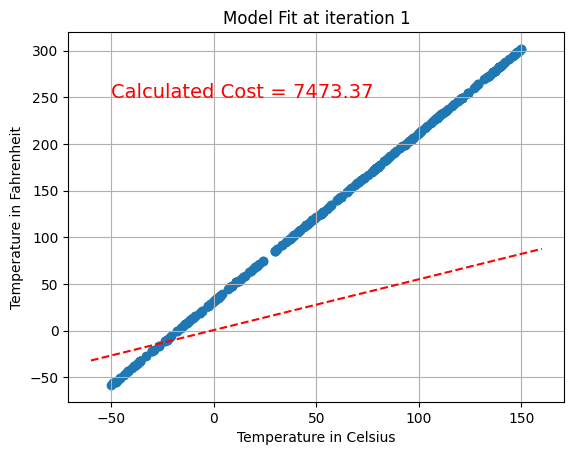

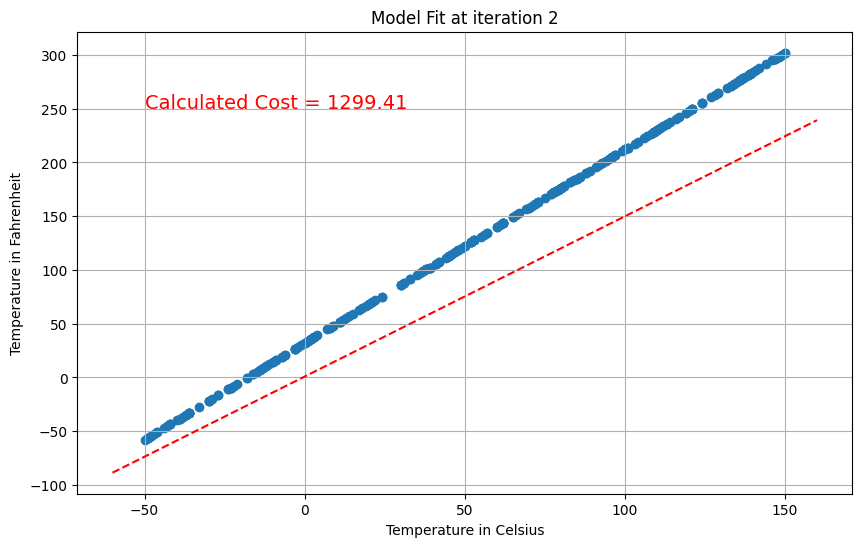

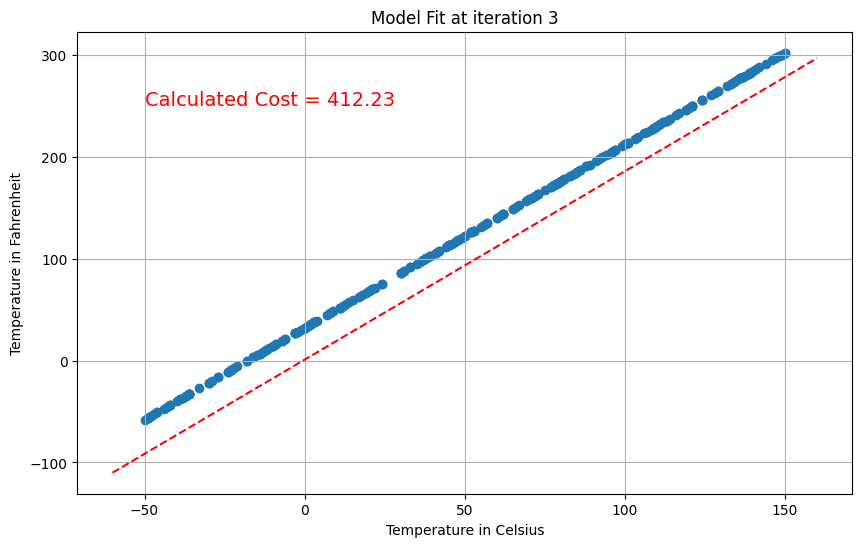

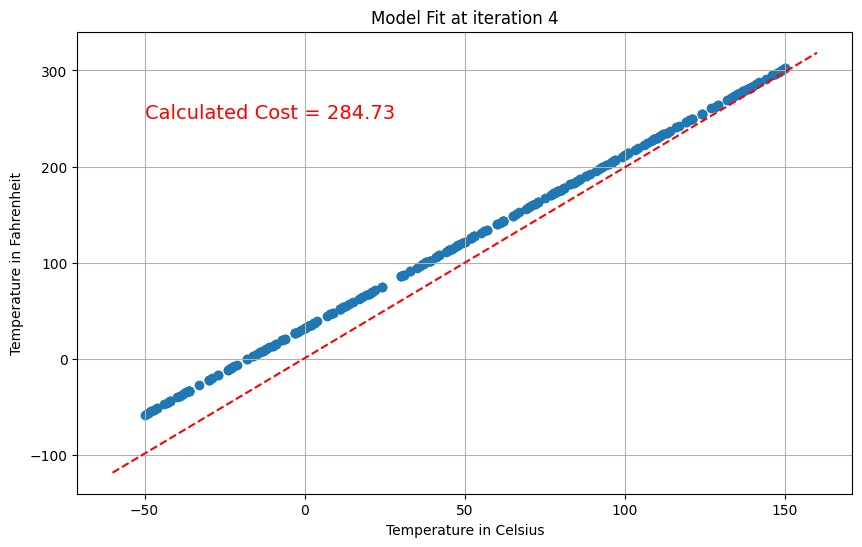

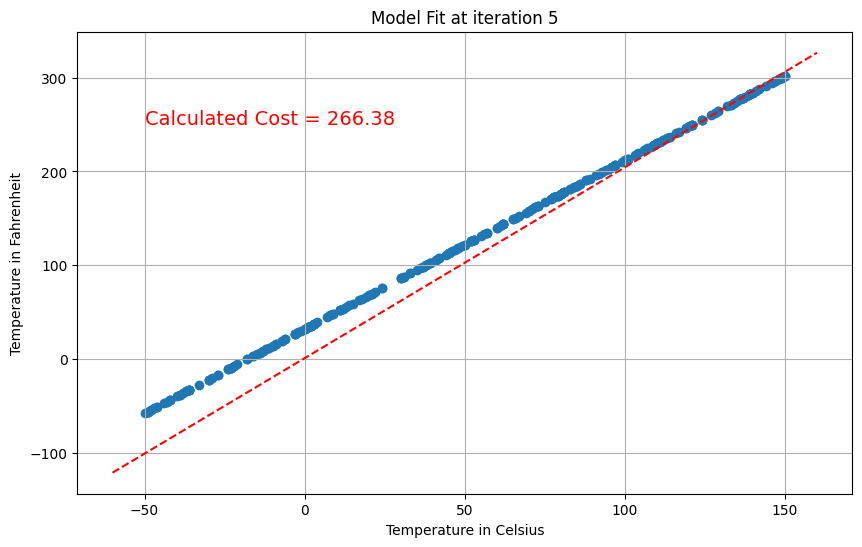

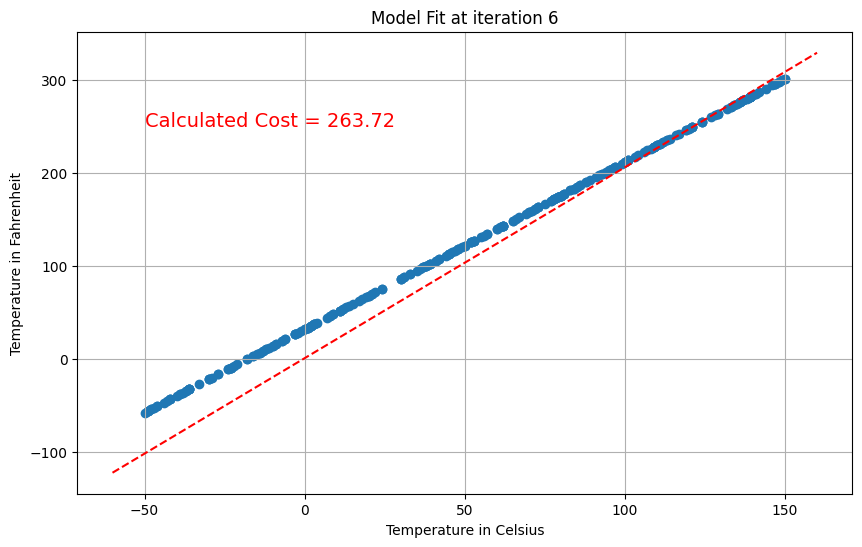

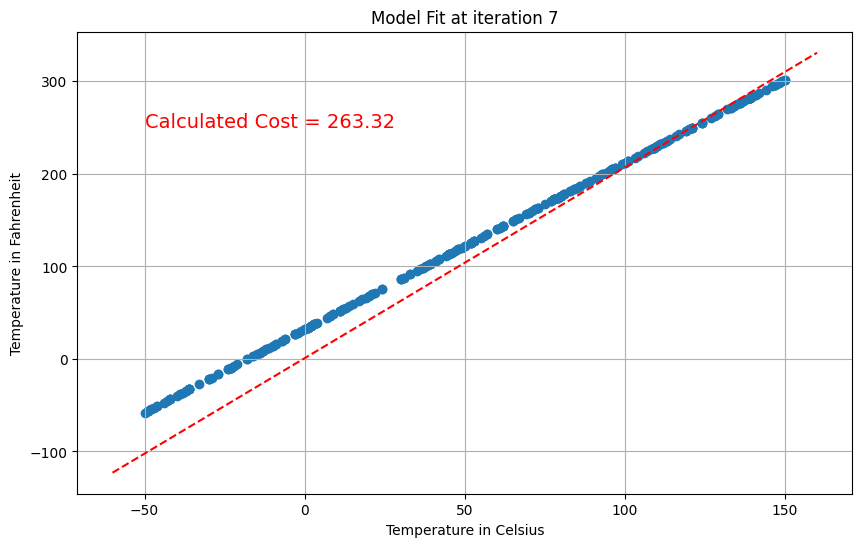

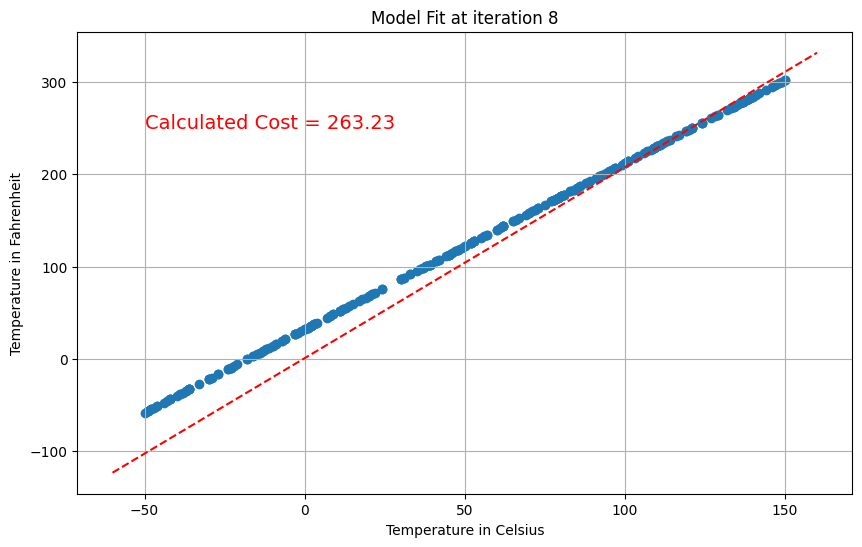

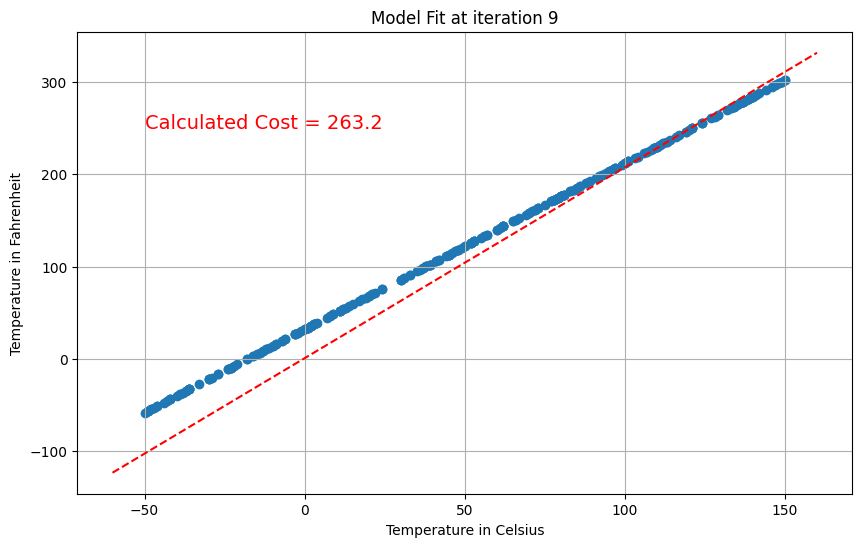

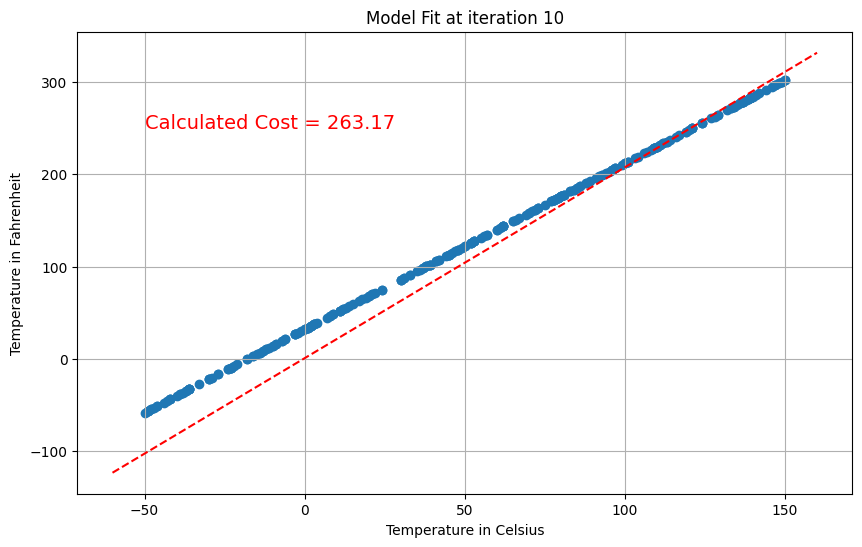

In [48]:
#Affichage courbe fit à chaque itération
for itr in range(0, iterations):
    plot_fit(data, w1_history[itr], w0_history[itr], cost_history[itr], itr, pdf=1)

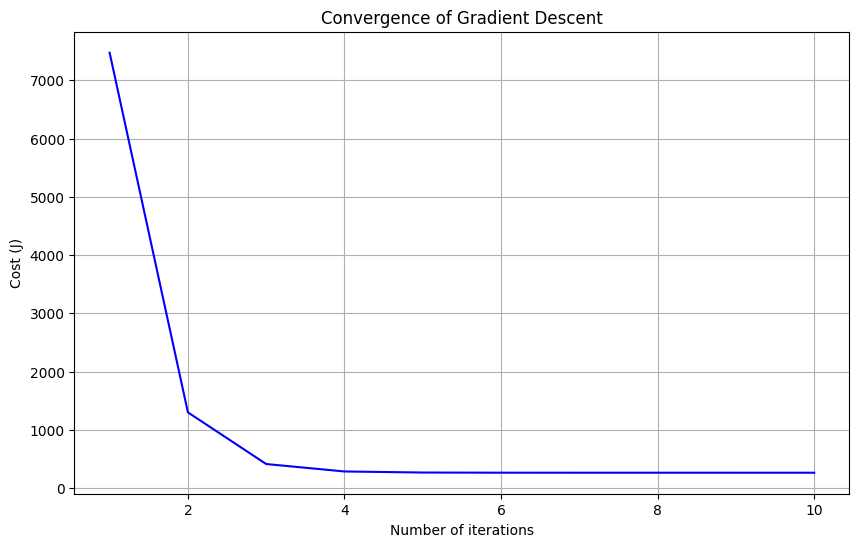

In [50]:
# Courbe coût
plot_cost_history(cost_history)

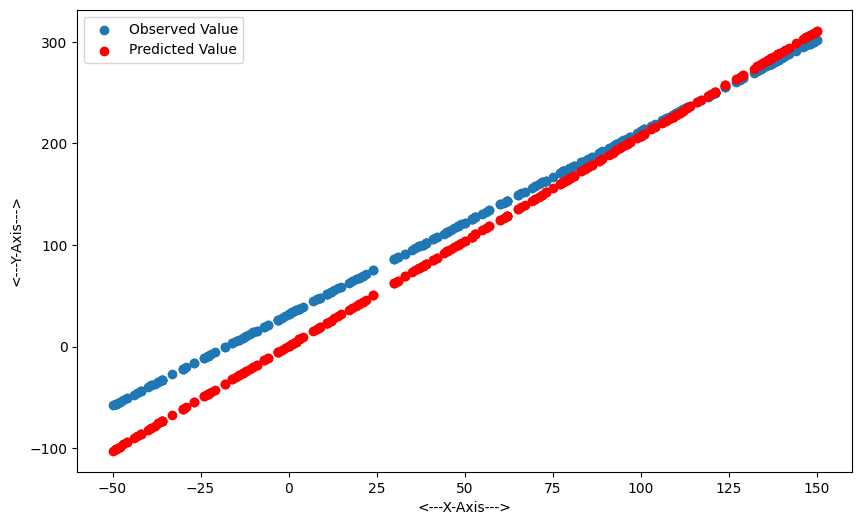

In [52]:
# Prédictions et visualisation finale
y_hat = predict_y(data.temp_c, w1, w0)
plot_actual_predicted(data.temp_c, data.temp_f, y_hat)